# Псков · квартальная модель BlocksNet

**Практика 2** дисциплины «Технологии ИИ в урбанистике» (ИДУ ИТМО). Яковлев Д. А., Цыганов В. А., группа C4107.

Ноутбук повторяет учебный пример [`pipeline.ipynb`](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb)
библиотеки **BlocksNet 1.0.0a9** для территории **городского округа Псков** (Псковская область, Россия) и добавляет
раздел про объекты культурного наследия (ОКН) и остановки транспорта.

| | |
|---|---|
| Территория | городской округ Псков, ≈ 95,7 км² |
| Метрическая СК | WGS 84 / UTM zone 35N (EPSG:32635) |
| Данные OSM | локальная выгрузка `pskov_oblast.pbf` (режим `pbf`) или Overpass API (режим `osm`) |
| ОКН и зоны охраны | подготовка — Денис Яковлев (проект PSKOKN) |
| Остановки транспорта | подготовка — Виктор Цыганов |
| Результаты | `data/results/*.geojson` → `scripts/build_dashboard.py` → `dashboard.html` |

**Как пользоваться.** Выполняйте ячейки сверху вниз. В двух местах стоит 🛑 **СТОП-ТОЧКА** — посмотрите на карту
и убедитесь, что граница и кварталы выглядят правдоподобно, прежде чем идти дальше.

## 0. Настройки

* `DATA_MODE = "pbf"` — все слои OSM берутся из подготовленных файлов `data/osm/*.geojson`
  (извлечены скриптом `scripts/prepare_data.py` из `pskov_oblast.pbf`), пешеходный граф строится из того же PBF.
  Работает без интернета и даёт одинаковый результат при каждом запуске.
* `DATA_MODE = "osm"` — как в исходном `pipeline.ipynb`: данные скачиваются через `osmnx`, граф — через `IduEdu`.
  Нужен интернет; результат зависит от текущего состояния OSM.
* `GRAPH_TYPE` — `"walk"` (пешеход, 5 км/ч) или, только в режиме `osm`, `"intermodal"` (пешеход + общественный транспорт).
* `USE_CACHE = True` — граф и матрица доступности сохраняются в `data/cache/` и при повторном запуске читаются оттуда.

In [1]:
import sys, json, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from pskov_blocksnet import config
from pskov_blocksnet.io import read_geojson, write_geojson

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_MODE = "pbf"     # "pbf" (офлайн, по умолчанию) или "osm" (онлайн, как в pipeline.ipynb)
GRAPH_TYPE = "walk"   # "walk"; в режиме "osm" можно "intermodal"
USE_CACHE = True

CRS = config.LOCAL_CRS
config.CACHE_DIR.mkdir(parents=True, exist_ok=True)
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Корень проекта:", ROOT)
print("Режим данных:", DATA_MODE, "| граф:", GRAPH_TYPE, "| CRS:", CRS)

Корень проекта: /home/claude/pskov-blocksnet
Режим данных: pbf | граф: walk | CRS: 32635


## 1. Граница территории

Граница городского округа Псков взята из OSM (relation административной границы), файл подготовлен в проекте PSKOKN.
В режиме `osm` её можно получить геокодированием, как в `pipeline.ipynb`.

Площадь территории: 95.5 км²


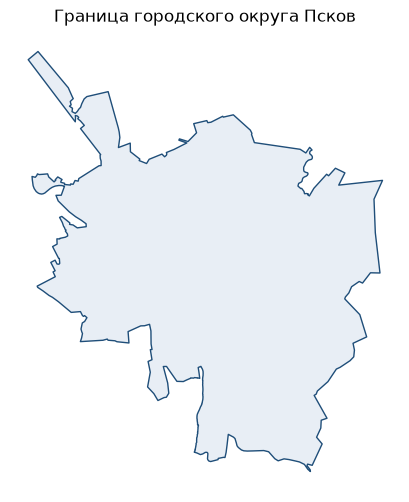

In [2]:
if DATA_MODE == "osm":
    import osmnx as ox
    boundary = ox.geocode_to_gdf("городской округ Псков, Псковская область, Россия")[["geometry"]]
else:
    boundary = read_geojson(config.INPUT_DIR / "boundary.geojson")

boundary = boundary.to_crs(CRS)
print(f"Площадь территории: {boundary.area.sum() / 1e6:.1f} км²")
ax = boundary.plot(color="#e8eef5", edgecolor="#1f4e79", figsize=(6, 6))
ax.set_title("Граница городского округа Псков"); ax.set_axis_off()

🛑 **СТОП-ТОЧКА 1.** Граница должна охватывать весь город (оба берега р. Великой, Завеличье, Запсковье, Любятово)
и не включать пригородные деревни Псковского района. Площадь ≈ 95–96 км². Если граница другая — остановитесь и разберитесь.

## 2. Исходные слои OSM

Набор тегов совпадает с разделом 1.1 `pipeline.ipynb`:
дороги (`highway` из списка), железные дороги (`railway=rail`), водные объекты; дополнительно — функциональные зоны
(`landuse=*`), здания (`building=*`) и школы (`amenity=school`).

In [3]:
if DATA_MODE == "osm":
    import osmnx as ox
    from pskov_blocksnet.osm_pbf import ROAD_HIGHWAYS
    poly = boundary.to_crs(4326).union_all()
    bc_tags = {
        "roads": {"highway": ROAD_HIGHWAYS, "service": ["living_street", "emergency_access"]},
        "railways": {"railway": "rail"},
        "water": {"riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True, "pond": True,
                  "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"], "landuse": "basin",
                  "water": "lake"},
    }
    water = ox.features_from_polygon(poly, bc_tags["water"])
    roads = ox.features_from_polygon(poly, bc_tags["roads"])
    railways = ox.features_from_polygon(poly, bc_tags["railways"])
    landuse = ox.features_from_polygon(poly, tags={"landuse": True}).reset_index(drop=True)[["geometry", "landuse"]]
    buildings = ox.features_from_polygon(poly, tags={"building": True}).reset_index(drop=True)
    schools = ox.features_from_polygon(poly, tags={"amenity": "school"}).reset_index(drop=True)
    schools["geometry"] = schools.to_crs(CRS).representative_point().to_crs(4326)
    water = water[water.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])]
    roads = roads[roads.geom_type.isin(["LineString", "MultiLineString"])]
    railways = railways[railways.geom_type.isin(["LineString", "MultiLineString"])]
    buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])]
else:
    roads = read_geojson(config.OSM_DIR / "roads.geojson")
    railways = read_geojson(config.OSM_DIR / "railways.geojson")
    water = read_geojson(config.OSM_DIR / "water.geojson")
    landuse = read_geojson(config.OSM_DIR / "landuse.geojson")
    buildings = read_geojson(config.OSM_DIR / "buildings.geojson")
    schools = read_geojson(config.OSM_DIR / "schools.geojson")

roads, railways, water, landuse, buildings, schools = [
    g.to_crs(CRS).reset_index(drop=True) for g in (roads, railways, water, landuse, buildings, schools)
]
pd.DataFrame({"слой": ["дороги", "ж/д", "вода", "функц. зоны", "здания", "школы"],
              "объектов": [len(g) for g in (roads, railways, water, landuse, buildings, schools)]})

,слой,объектов
0,дороги,2195
1,ж/д,252
2,вода,116
3,функц. зоны,1183
4,здания,15265
5,школы,42


## 3. Нарезка кварталов

`preprocess_urban_objects` приводит дороги, железные дороги и воду к двум слоям — **линии** (режут территорию) и
**полигоны** (вычитаются из неё). `cut_urban_blocks` режет границу этими объектами — получаются кварталы.
`postprocess_urban_blocks` исправляет невалидные геометрии.

Наше дополнение к примеру: отбрасываем «осколки» площадью меньше 100 м² — это артефакты пересечения линий,
а не кварталы (порог `MIN_BLOCK_AREA`).

In [4]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
from blocksnet.blocks.postprocessing import postprocess_urban_blocks

MIN_BLOCK_AREA = 100  # м²

lines, polygons = preprocess_urban_objects(roads, railways, water)
blocks_raw = cut_urban_blocks(boundary[["geometry"]], lines, polygons)
blocks = postprocess_urban_blocks(blocks_raw)
n_before = len(blocks)
blocks = blocks[blocks.area >= MIN_BLOCK_AREA].reset_index(drop=True)
blocks.index.name = "block_id"
print(f"Кварталов после нарезки: {n_before}; после удаления осколков < {MIN_BLOCK_AREA} м²: {len(blocks)}")
print(f"Площадь кварталов: {blocks.area.sum() / 1e4:,.1f} га; медиана квартала {blocks.area.median() / 1e4:.2f} га")

2026-10-22 01:22:41.773 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema


2026-10-22 01:22:41.783 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema


2026-10-22 01:22:41.789 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


2026-10-22 01:22:41.798 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema


2026-10-22 01:22:41.804 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema


2026-10-22 01:22:41.817 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema


2026-10-22 01:22:41.825 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema


2026-10-22 01:22:41.825 | WARNING  | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:71 - Creating empty buildings


2026-10-22 01:22:41.929 | SUCCESS  | blocksnet.blocks.cutting.processing.core:cut_urban_blocks:26 - 933 blocks are successfully cut


Кварталов после нарезки: 933; после удаления осколков < 100 м²: 902
Площадь кварталов: 9,262.4 га; медиана квартала 1.40 га


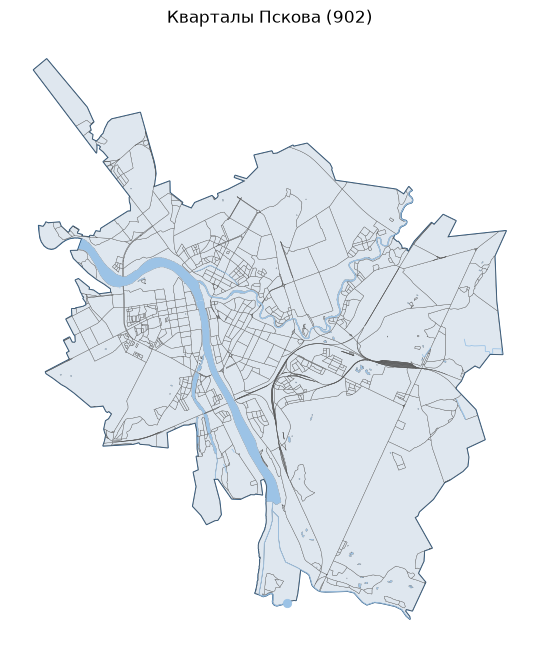

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))
boundary.plot(ax=ax, color="none", edgecolor="#1f4e79", linewidth=1.2)
blocks.plot(ax=ax, color="#dfe7ef", edgecolor="#555", linewidth=0.25)
water.clip(boundary).plot(ax=ax, color="#9cc3e6", linewidth=0.6)
ax.set_title(f"Кварталы Пскова ({len(blocks)})"); ax.set_axis_off()

🛑 **СТОП-ТОЧКА 2.** Проверьте кварталы: границы проходят по улицам, железной дороге и рекам Великой и Пскове;
нет гигантских кварталов, захвативших несколько районов; нет «решета» из мелких треугольников.
Крупные кварталы на окраинах (лес, поля, аэродром) — нормально: там мало улиц.

## 4. Какие метрики есть в BlocksNet (простыми словами)

BlocksNet считает показатели **на уровне квартала**. Модули библиотеки:

| Модуль | Что делает |
|---|---|
| `blocks.cutting` / `postprocessing` | нарезает территорию на кварталы по улицам, ж/д и воде |
| `blocks.assignment` | определяет функцию квартала (жилая, деловая…) по слою функциональных зон |
| `blocks.aggregation` | суммирует объекты (здания, школы) внутри кварталов |
| `relations` | связи между кварталами: матрица времени в пути, расстояний, смежности |
| `preprocessing.imputing` | заполняет пропуски: этажность, площади, население, вместимость сервисов |
| `analysis.provision` | обеспеченность сервисами с учётом конкуренции за места и доступности |
| `analysis.indicators` | плотность застройки (FSI, GSI, MXI, L, OSR) и социально-экономические индикаторы |
| `analysis.morphotypes` | типы застройки: Spacematrix и классификация «Стрелки» |
| `analysis.network` | доступность, связность, центральность сети |
| `analysis.diversity`, `services`, `land_use`, `centrality` | разнообразие, плотность сервисов, соседство функций |
| `optimization`, `synthesis`, `machine_learning` | сценарное планирование, генерация, ML-модели |

**Показатели из `pipeline.ipynb`, которые считаем в этом ноутбуке** (и выводим в дашборд):

| № | Показатель | Колонка | Единицы | Функция BlocksNet |
|---|---|---|---|---|
| 1 | Доли функций в квартале | `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` | доля 0–1 | `assign_land_use` |
| 2 | Преобладающая функция | `land_use` | категория | `assign_land_use` |
| 3 | Время в пути между кварталами | матрица `acc_mx` | мин | `calculate_accessibility_matrix` |
| 4 | Число жилых зданий | `is_living` | шт. | `aggregate_objects` |
| 5 | Этажность (сумма по зданиям) | `number_of_floors` | этажей | `aggregate_objects` |
| 6 | Площадь застройки | `footprint_area` | м² | `impute_buildings` + `aggregate_objects` |
| 7 | Суммарная поэтажная площадь | `build_floor_area` | м² | то же |
| 8 | Жилая / нежилая площадь | `living_area`, `non_living_area` | м² | то же |
| 9 | Население (оценка) | `population` | чел. | то же |
| 10 | Число школ и их вместимость | `schools_count`, `schools_capacity` | шт., мест | `impute_services` + `aggregate_objects` |
| 11 | Спрос на места в школах | `demand` | мест | `competitive_provision` (120 мест на 1000 жителей) |
| 12 | Удовлетворённый спрос в норме доступности / за её пределами / неудовлетворённый | `demand_within`, `demand_without`, `demand_left` | мест | `competitive_provision` |
| 13 | Остаток мест | `capacity_left` | мест | `competitive_provision` |
| 14 | Обеспеченность строгая / мягкая | `provision_strong`, `provision_weak` | доля 0–1 | `competitive_provision` |
| 15 | Потоки «квартал → школа» | `provision_links.geojson` | детей | `competitive_provision` |
| 16 | Плотность застройки | `fsi`, `gsi`, `mxi`, `l`, `osr` | м²/м², доля, этажи | `calculate_density_indicators` |
| 17 | Морфотип Spacematrix | `spacematrix_morphotype` | категория | `get_spacematrix_morphotypes` |
| 18 | Морфотип «Стрелки» | `strelka_morphotype` | категория | `get_strelka_morphotypes` |
| 19 | Доступность с учётом площади | `area_accessibility` | мин | `area_accessibility` |

Дополнительно (не из `pipeline.ipynb`): плотность населения (чел./га), средняя этажность, число ОКН и доля
территории в зонах охраны, остановки транспорта.

## 5. Землепользование

Слой `landuse=*` из OSM сопоставляется с классами `LandUse` BlocksNet по словарю правил. Правила из `pipeline.ipynb`
дополнены тегами, встречающимися в Пскове: `railway`, `allotments`, `education`, `meadow`, `greenhouse_horticulture`,
`quarry`, `village_green`, `winter_sports`. Для каждого квартала считается доля площади каждой функции, а
преобладающая (`land_use`) назначается, если её доля достаточна; иначе — `None` («не определено»).

In [6]:
from blocksnet.enums import LandUse
from blocksnet.blocks.assignment import assign_land_use

rules = {
    # как в pipeline.ipynb
    "commercial": LandUse.BUSINESS, "industrial": LandUse.INDUSTRIAL, "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL, "residential": LandUse.RESIDENTIAL, "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION, "farmland": LandUse.AGRICULTURE, "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL, "forest": LandUse.RECREATION, "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL, "flowerbed": LandUse.RECREATION, "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    # дополнено для Пскова
    "railway": LandUse.TRANSPORT, "allotments": LandUse.AGRICULTURE, "education": LandUse.BUSINESS,
    "meadow": LandUse.RECREATION, "greenhouse_horticulture": LandUse.AGRICULTURE, "quarry": LandUse.INDUSTRIAL,
    "village_green": LandUse.RECREATION, "winter_sports": LandUse.RECREATION,
}
functional_zones = landuse.rename(columns={"landuse": "functional_zone"})[["functional_zone", "geometry"]]
unmapped = sorted(set(functional_zones.functional_zone) - set(rules))
print("Теги landuse без правила (не учитываются):", unmapped or "нет")

blocks_lu = assign_land_use(blocks, functional_zones.reset_index(drop=True), rules)
LU_COLUMNS = [lu.value for lu in LandUse]
blocks_lu["land_use"] = blocks_lu["land_use"].apply(lambda v: v.value if isinstance(v, LandUse) else v)
blocks_lu["land_use"].value_counts(dropna=False).rename("кварталов").to_frame()

2026-10-22 01:22:42.491 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: reservoir


Теги landuse без правила (не учитываются): ['reservoir']


,кварталов
land_use,
residential,495
None,183
transport,87
industrial,60
recreation,43
business,20
special,13
agriculture,1


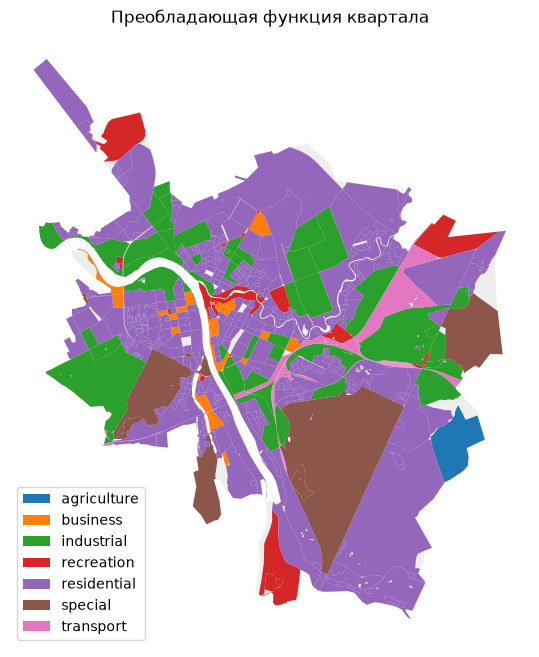

In [7]:
ax = blocks_lu.plot(color="#eee", figsize=(8, 8))
blocks_lu.dropna(subset=["land_use"]).plot(column="land_use", legend=True, ax=ax, cmap="tab10",
                                           legend_kwds={"loc": "lower left"})
ax.set_title("Преобладающая функция квартала"); ax.set_axis_off()

## 6. Матрица времени в пути

Строим граф улично-дорожной сети и считаем матрицу `n × n`: время (мин) от репрезентативной точки каждого квартала
до каждого другого.

* Режим `pbf`: **пешеходный граф** из `pskov_oblast.pbf` (дороги, тротуары, тропинки), скорость 5 км/ч, буфер 1 км вокруг
  границы. Граф приведён к формату IduEdu (`crs`, `x`, `y`, `time_min`, узлы 0..N-1), поэтому матрицу считает та же
  функция BlocksNet, что и в примере.
* Режим `osm`: `get_accessibility_graph(boundary, GRAPH_TYPE)` — граф IduEdu из Overpass (как в `pipeline.ipynb`, где
  используется `intermodal`).

In [8]:
from blocksnet.relations import calculate_accessibility_matrix, get_accessibility_graph

graph_path = config.CACHE_DIR / f"graph_{DATA_MODE}_{GRAPH_TYPE}.pickle"
acc_path = config.CACHE_DIR / f"acc_mx_{DATA_MODE}_{GRAPH_TYPE}_{len(blocks)}.parquet"

if USE_CACHE and acc_path.exists():
    acc_mx = pd.read_parquet(acc_path)
    acc_mx.columns = acc_mx.columns.astype(int)
    print("Матрица прочитана из кэша:", acc_path.name)
else:
    if USE_CACHE and graph_path.exists():
        graph = pickle.load(open(graph_path, "rb"))
    elif DATA_MODE == "osm":
        graph = get_accessibility_graph(boundary, GRAPH_TYPE)
    else:
        from pskov_blocksnet.osm_pbf import build_walk_graph
        graph = build_walk_graph(config.PBF_PATH, boundary, CRS, speed_kmh=config.WALK_SPEED_KMH)
    pickle.dump(graph, open(graph_path, "wb"))
    print(f"Граф: {graph.number_of_nodes()} узлов, {graph.number_of_edges()} рёбер")
    acc_mx = calculate_accessibility_matrix(blocks, graph)
    acc_mx.to_parquet(acc_path)

acc_mx = acc_mx.astype("float32")
vals = acc_mx.values[~np.eye(len(acc_mx), dtype=bool)]
print(f"Матрица {acc_mx.shape}; время между кварталами: медиана {np.median(vals):.1f} мин, "
      f"максимум {vals.max():.1f} мин; недостижимых пар: {np.isinf(vals).sum()}")
acc_mx.iloc[:5, :5]

2026-10-22 01:22:46.977 | INFO     | pskov_blocksnet.osm_pbf:build_walk_graph:161 - Пешеходный граф: 44721 узлов, 102668 рёбер


Граф: 44721 узлов, 102668 рёбер


Матрица (902, 902); время между кварталами: медиана 60.2 мин, максимум 222.4 мин; недостижимых пар: 0


,0,1,2,3,4
0,0.000000,8.671875,124.8750,126.0625,66.5625
1,8.671875,0.000000,116.5625,117.7500,59.3125
2,124.875000,116.562500,0.0000,13.7500,150.1250
3,126.062500,117.750000,13.7500,0.0000,151.3750
4,66.562500,59.312500,150.1250,151.3750,0.0000


## 7. Здания и население

Как в `pipeline.ipynb`:

* `is_living` — здание жилое, если тег `building` ∈ {residential, house, apartments, detached, terrace, dormitory,
  semidetached_house};
* `number_of_floors` — из тега `building:levels`;
* `impute_buildings` заполняет пропуски: площадь застройки = площадь контура, этажность по умолчанию = 1,
  поэтажная площадь = этажи × контур, жилая = 0,9 × поэтажная (только жилые), население = жилая площадь / 30 м²/чел.

⚠️ В OSM по Пскову этажность указана лишь у части зданий, а у 70 % зданий тег `building=yes` (тип не указан) —
такие здания считаются нежилыми. Поэтому население — **оценка модели**, её надо сравнить с официальной численностью.

In [9]:
from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects

bld = buildings.copy()
bld["is_living"] = bld["building"].isin(config.IS_LIVING_TAGS)
bld["number_of_floors"] = pd.to_numeric(bld["building:levels"], errors="coerce")
floors_known_share = bld["number_of_floors"].notna().mean()

bld = impute_buildings(bld, default_living_demand=config.DEFAULT_LIVING_DEMAND)
population_total = bld["population"].sum()
print(f"Зданий: {len(bld):,}; жилых: {bld.is_living.sum():,}; этажность известна у {floors_known_share:.1%}")
print(f"Расчётное население: {population_total:,.0f} чел. (для сравнения: тег population границы в OSM — 209 426)")

buildings_blocks = aggregate_objects(blocks, bld)[0]
buildings_blocks.drop(columns="geometry").describe().T[["mean", "max"]]

2026-10-22 01:22:59.456 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None


2026-10-22 01:22:59.457 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None


2026-10-22 01:22:59.458 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None


2026-10-22 01:22:59.458 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None


2026-10-22 01:22:59.459 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


2026-10-22 01:22:59.515 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-22 01:22:59.520 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Зданий: 15,265; жилых: 2,940; этажность известна у 17.8%
Расчётное население: 194,622 чел. (для сравнения: тег population границы в OSM — 209 426)


,mean,max
is_living,3.259424,92.000000
number_of_floors,24.409091,773.000000
footprint_area,6571.665396,226511.485530
build_floor_area,14413.430447,387296.419563
living_area,6521.257135,316953.185079
non_living_area,7892.173312,254845.680956
population,215.767184,10551.000000
count,16.921286,681.000000


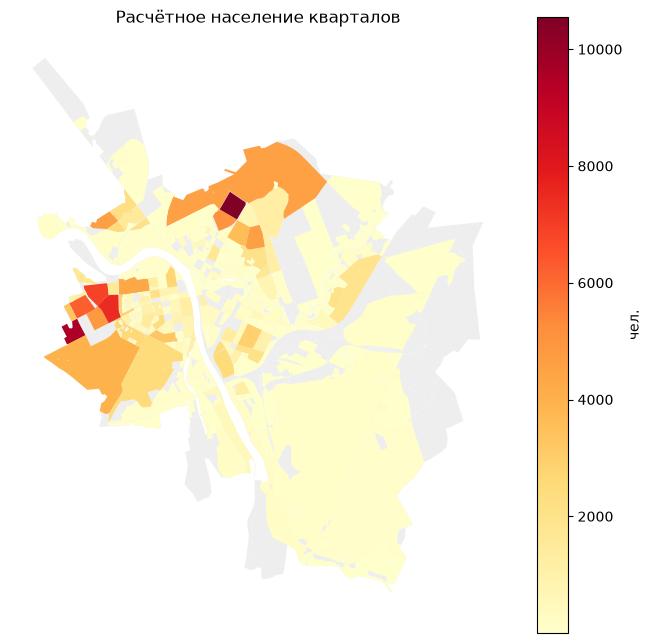

In [10]:
ax = blocks.plot(color="#eee", figsize=(8, 8))
buildings_blocks[buildings_blocks.population > 0].plot("population", legend=True, cmap="YlOrRd", ax=ax,
                                                        legend_kwds={"label": "чел."})
ax.set_title("Расчётное население кварталов"); ax.set_axis_off()

## 8. Школы

Школы — объекты `amenity=school` (точки и контуры → репрезентативная точка). При подготовке исключены
не общеобразовательные учреждения (футбольная школа, «Кибершкола», центр внешкольной работы) и дубли «точка внутри
контура». `impute_services(…, "school")` ставит вместимость **250 мест** (минимальная типовая единица из справочника
BlocksNet) всем школам без тега `capacity`.

⚠️ Реальные школы Пскова обычно вмещают 500–1200 учеников, поэтому вместимость **оценочная и занижена**;
дефицит мест ниже — следствие этого допущения, а не реальная нехватка.

In [11]:
from blocksnet.preprocessing.imputing import impute_services

schools_in = schools[["name", "capacity", "geometry"]].copy()
schools_in["capacity"] = pd.to_numeric(schools_in["capacity"], errors="coerce")
schools_in["capacity_is_estimated"] = schools_in["capacity"].isna()
schools_imp = impute_services(schools_in[["capacity", "geometry"]].copy(), config.SCHOOL_SERVICE)
schools_imp["name"] = schools_in["name"].values
schools_imp["capacity_is_estimated"] = schools_in["capacity_is_estimated"].values

schools_blocks = aggregate_objects(blocks, schools_imp[["capacity", "geometry"]])[0]
schools_blocks = schools_blocks.rename(columns={"capacity": "schools_capacity", "count": "schools_count"})
print(f"Школ: {len(schools_imp)}; вместимость из OSM: {(~schools_imp.capacity_is_estimated).sum()}, "
      f"оценочная (250): {schools_imp.capacity_is_estimated.sum()}; всего мест: {schools_imp.capacity.sum():,.0f}")

2026-10-22 01:22:59.882 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-22 01:22:59.884 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Школ: 42; вместимость из OSM: 1, оценочная (250): 41; всего мест: 10,615


## 9. Обеспеченность школами (конкурентная модель)

`competitive_provision` распределяет детей по школам с учётом **вместимости** и **нормативной доступности**:

* спрос = население × 120 / 1000 (норматив BlocksNet для `school`);
* нормативная доступность — 15 мин по графу;
* задача линейного программирования (PuLP): сначала дети занимают места в школе своего квартала, затем — в школах
  в пределах 15 мин; что не поместилось — `demand_left`.

Показатели: `provision_strong` = доля спроса, удовлетворённая в норме доступности; `provision_weak` — с учётом мест
за пределами нормы. Значение `NaN` — в квартале нет населения (нет спроса).

In [12]:
from blocksnet.config import service_types_config
from blocksnet.analysis.provision import competitive_provision

_, demand_norm, accessibility_norm = service_types_config[config.SCHOOL_SERVICE].values()
print(f"Норматив: {demand_norm} мест на 1000 жителей, доступность {accessibility_norm} мин")

prov_input = buildings_blocks[["population"]].join(schools_blocks[["schools_capacity"]].rename(
    columns={"schools_capacity": "capacity"}))
prov_df, links_df = competitive_provision(prov_input, acc_mx, accessibility_norm, demand_norm)

tot = prov_df[["demand", "capacity", "demand_within", "demand_without", "demand_left", "capacity_left"]].sum()
print(f"Спрос {tot.demand:,.0f} мест, вместимость {tot.capacity:,.0f}; удовлетворено в норме {tot.demand_within:,.0f} "
      f"({tot.demand_within / tot.demand:.1%}), вне нормы {tot.demand_without:,.0f}, не удовлетворено {tot.demand_left:,.0f}")
prov_df[prov_df.demand > 0].head()

2026-10-22 01:22:59.919 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-10-22 01:22:59.919 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-10-22 01:22:59.929 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-22 01:22:59.936 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-10-22 01:23:00.056 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Норматив: 120 мест на 1000 жителей, доступность 15 мин
Спрос 23,524 мест, вместимость 10,615; удовлетворено в норме 8,479 (36.0%), вне нормы 0, не удовлетворено 15,045


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,3,0,3,0,0,0,0,0,0.0,0.0
3,1150,0,1150,0,0,0,0,0,0.0,0.0
6,2,0,0,2,0,0,0,0,1.0,1.0
8,4,0,0,4,0,0,0,0,1.0,1.0
9,298,0,0,298,0,0,0,0,1.0,1.0


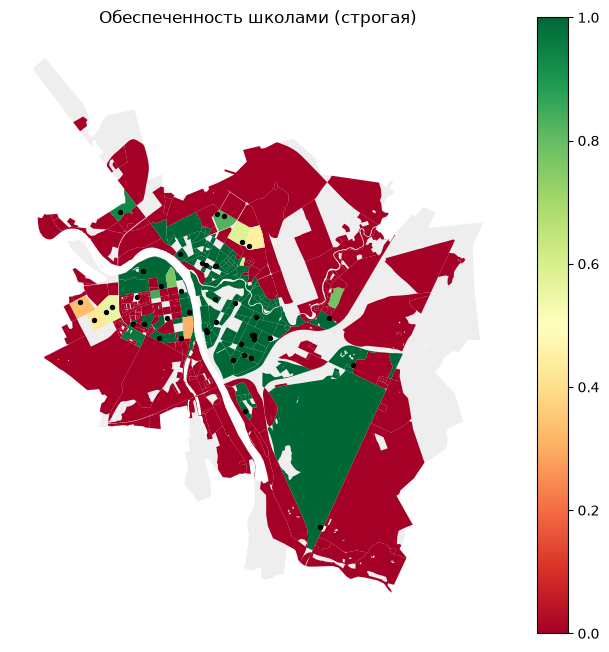

In [13]:
ax = blocks.plot(color="#eee", figsize=(8, 8))
blocks.join(prov_df).dropna(subset=["provision_strong"]).plot("provision_strong", cmap="RdYlGn", vmin=0, vmax=1,
                                                              legend=True, ax=ax)
schools_imp.plot(ax=ax, color="black", markersize=8)
ax.set_title("Обеспеченность школами (строгая)"); ax.set_axis_off()

## 10. Плотность застройки

`calculate_density_indicators` (нужна площадь квартала `site_area`, м²):

* **FSI** (Floor Space Index) — поэтажная площадь / площадь квартала, м²/м²;
* **GSI** (Ground Space Index) — площадь застройки / площадь квартала, доля;
* **L** — средняя этажность = FSI / GSI;
* **OSR** (Open Space Ratio) — незастроенная площадь на 1 м² поэтажной, (1 − GSI) / FSI;
* **MXI** (Mixed-use Index) — доля жилой площади в поэтажной;
* `share_living`, `share_non_living` — служебные доли BlocksNet (могут быть > 1 из-за того, что жилая площадь
  считается от поэтажной с коэффициентом; в дашборд не выводим).

In [14]:
from blocksnet.analysis.indicators import calculate_density_indicators

buildings_blocks["site_area"] = buildings_blocks.area
density_df = calculate_density_indicators(buildings_blocks)
density_df = density_df.replace([np.inf, -np.inf], np.nan)
city_fsi = buildings_blocks.build_floor_area.sum() / buildings_blocks.site_area.sum()
city_gsi = buildings_blocks.footprint_area.sum() / buildings_blocks.site_area.sum()
print(f"FSI города: {city_fsi:.3f}; GSI города: {city_gsi:.3f}")
density_df[["fsi", "gsi", "l", "osr", "mxi"]].describe().T

FSI города: 0.140; GSI города: 0.064


,count,mean,std,min,25%,50%,75%,max
fsi,902.0,0.210820,0.407794,0.000000,0.000000,0.062386,0.161821,3.972293
gsi,902.0,0.081388,0.092189,0.000000,0.000000,0.060375,0.132332,0.517312
l,569.0,2.055920,1.890572,1.000000,1.000000,1.000000,2.411637,15.424218
osr,569.0,31.351184,199.655567,0.140633,1.841845,6.992779,12.097131,3815.082129
mxi,569.0,0.304423,0.350126,0.000000,0.000000,0.096479,0.640159,0.900000


## 11. Морфотипы застройки

* **Spacematrix** (Berghauser Pont & Haupt): кварталы кластеризуются (k-means) по FSI, GSI/L и MXI, кластеры
  интерпретируются как «малоэтажная / среднеэтажная / многоэтажная», «низкой / высокой плотности»,
  «жилая / нежилая / смешанная».
* **«Стрелка»**: правила по этажности и плотности из методики КБ «Стрелка» (индивидуальная жилая, модельная
  малоэтажная, центральная модель, советский микрорайон, современный микрорайон и т.д.).

Кварталы без застройки морфотипа не получают.

In [15]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
strelka_df = get_strelka_morphotypes(density_df)
display(spacematrix_df.morphotype.value_counts().rename("Spacematrix").to_frame())
display(strelka_df.morphotype.value_counts().rename("Стрелка").to_frame())
spacematrix_clusters

,Spacematrix
morphotype,
low-rise low-density non-residential,299
low-rise low-density mixed-use,77
mid-rise low-density residential,73
low-rise low-density residential,66
mid-rise low-density non-residential,25
mid-rise residential,17
high-mid-rise residential,9
high-mid-rise high-density residential,3


,Стрелка
morphotype,
low-rise non-residential,255
low-rise model,135
individual residential,87
mid-rise,68
high-rise modern microdistrict,10
central model,7
mid-rise block,5
mid-rise non-residential,1
high-rise soviet microdistrict,1


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.092196,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,5.000000,0.976930,0.878345,mid-rise,low-density,residential,mid-rise low-density residential
2,1.000000,0.098761,0.770849,low-rise,low-density,residential,low-rise low-density residential
3,9.000000,1.762919,0.900000,high-mid-rise,None,residential,high-mid-rise residential
4,3.000000,0.744413,0.078518,mid-rise,low-density,non-residential,mid-rise low-density non-residential
5,1.000000,0.096661,0.377356,low-rise,low-density,mixed-use,low-rise low-density mixed-use
6,2.566185,0.436340,0.413237,low-rise,low-density,mixed-use,low-rise low-density mixed-use
7,5.000000,1.466740,0.900000,mid-rise,None,residential,mid-rise residential
8,1.567529,0.307945,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential


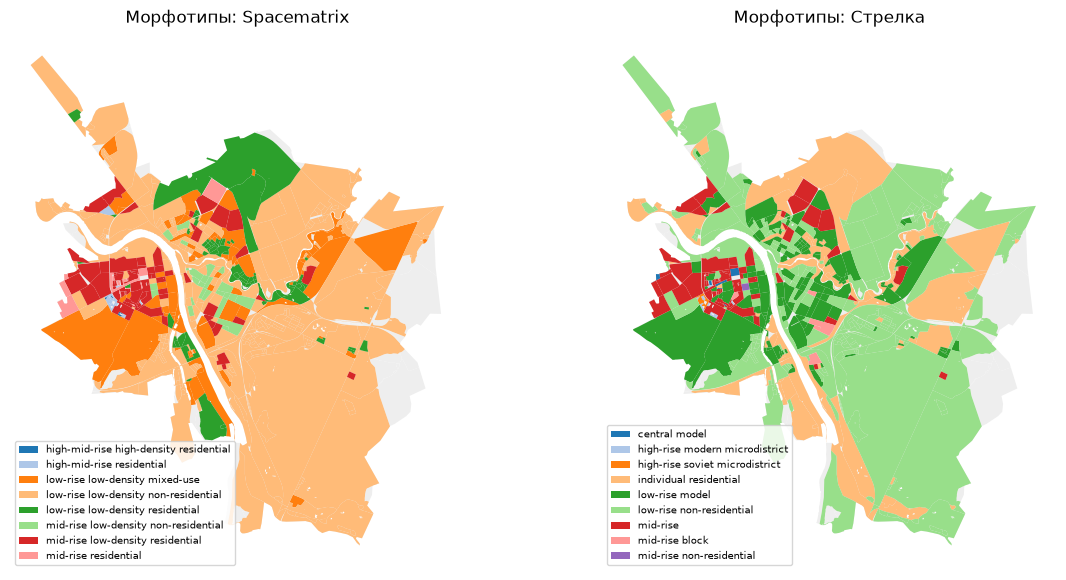

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (title, df) in zip(axes, [("Spacematrix", spacematrix_df), ("Стрелка", strelka_df)]):
    blocks.plot(color="#eee", ax=ax)
    blocks.join(df).dropna(subset=["morphotype"]).plot("morphotype", legend=True, ax=ax, cmap="tab20",
                                                       legend_kwds={"loc": "lower left", "fontsize": 7})
    ax.set_title(f"Морфотипы: {title}"); ax.set_axis_off()

## 12. Доступность с учётом площади кварталов

`area_accessibility` — для каждого квартала среднее время (мин) до всех остальных кварталов, взвешенное по их
площади. Чем меньше значение, тем «центральнее» квартал в пешеходной сети. Это не время до ближайшего сервиса!

count    902.0
mean      81.3
std       14.0
min       61.9
25%       70.1
50%       78.4
75%       87.9
max      142.0
Name: area_accessibility, dtype: float64


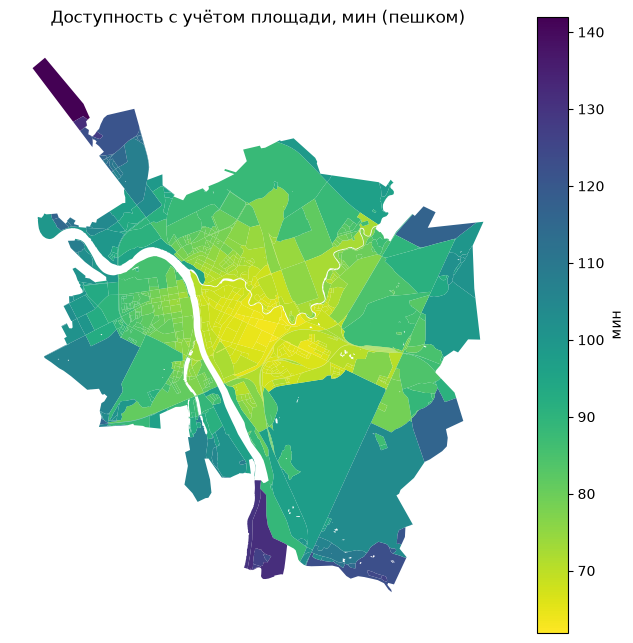

In [17]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc = area_accessibility(acc_mx, buildings_blocks)
print(area_acc.area_accessibility.describe().round(1))
ax = blocks.join(area_acc).plot("area_accessibility", cmap="viridis_r", legend=True, figsize=(8, 8),
                                legend_kwds={"label": "мин"})
ax.set_title("Доступность с учётом площади, мин (пешком)"); ax.set_axis_off()

## 13. Дополнительно: культурное наследие и транспорт

Слои из других проектов, обрезанные по границе Пскова:

* **ОКН** — единый реестр (ЕГРОКН) и данные Комитета по охране ОКН Псковской области: точки и контуры объектов,
  зоны охраны. Подготовка — **Денис Яковлев** (проект PSKOKN).
* **Остановки** — OSM `highway=bus_stop`, Яндекс.Расписания, ж/д платформы и станции. Подготовка — **Виктор Цыганов**.

По кварталам считаем: число ОКН (точки внутри квартала), из них федерального значения, долю площади квартала в зонах
охраны ОКН, число остановок и расстояние от квартала до ближайшей остановки (по прямой, м).

In [18]:
heritage_pts = read_geojson(config.INPUT_DIR / "heritage_points.geojson", CRS)
zones = read_geojson(config.INPUT_DIR / "heritage_protection_zones.geojson", CRS)
stops = read_geojson(config.INPUT_DIR / "transport_stops.geojson", CRS)

extra = pd.DataFrame(index=blocks.index)
j = heritage_pts.sjoin(blocks[["geometry"]], predicate="within")
extra["okn_count"] = j.groupby("block_id").size()
extra["okn_federal"] = j[j["Category"].fillna("").str.contains("федерал", case=False)].groupby("block_id").size()
extra["okn_unesco"] = j[j["UNESCO"].fillna("").str.lower().str.strip() == "да"].groupby("block_id").size()
zones_union = zones.union_all()
extra["protection_zone_share"] = blocks.intersection(zones_union).area / blocks.area
stops_bus = stops[stops["source"] != "Яндекс.Расписания"]  # точки Яндекса дублируют OSM-остановки
extra["stops_count"] = stops_bus.sjoin(blocks[["geometry"]], predicate="within").groupby("block_id").size()
rep = blocks.representative_point()
nearest = gpd.GeoDataFrame(geometry=rep, crs=CRS).sjoin_nearest(stops_bus[["geometry"]], distance_col="d")
extra["nearest_stop_m"] = nearest.groupby(level=0)["d"].min()
extra = extra.fillna({"okn_count": 0, "okn_federal": 0, "okn_unesco": 0, "stops_count": 0}).astype(
    {"okn_count": int, "okn_federal": int, "okn_unesco": int, "stops_count": int})
print(f"ОКН (точки) в кварталах: {extra.okn_count.sum()} из {len(heritage_pts)}; "
      f"кварталов с ОКН: {(extra.okn_count > 0).sum()}; в зонах охраны (>50% площади): "
      f"{(extra.protection_zone_share > 0.5).sum()}")
extra.describe().T[["mean", "max"]]

ОКН (точки) в кварталах: 434 из 435; кварталов с ОКН: 118; в зонах охраны (>50% площади): 14


,mean,max
okn_count,0.481153,22.000000
okn_federal,0.201774,16.000000
okn_unesco,0.011086,2.000000
protection_zone_share,0.015046,1.000000
stops_count,0.284922,8.000000
nearest_stop_m,350.343147,3896.205239


## 14. Итоговый слой и экспорт в GeoJSON

Собираем все показатели в один слой кварталов и сохраняем результаты в `data/results/`. Дашборд
(`scripts/build_dashboard.py`) читает **только** эти файлы — без повторной загрузки данных и расчётов.

| Файл | Содержимое |
|---|---|
| `blocks.geojson` | кварталы со всеми показателями |
| `schools.geojson` | школы с вместимостью и флагом «оценочная» |
| `provision_links.geojson` | потоки «квартал → квартал со школой» (детей) |
| `heritage_points.geojson`, `heritage_protection_zones.geojson`, `transport_stops.geojson`, `boundary.geojson` | контекстные слои |
| `summary.json` | итоги по городу, параметры моделей, источники и ограничения |

In [19]:
result = blocks.copy()
result["site_area_ha"] = result.area / 1e4
result = result.join(blocks_lu[LU_COLUMNS + ["land_use"]])
result = result.join(buildings_blocks[["count", "is_living", "number_of_floors", "footprint_area", "build_floor_area",
                                       "living_area", "non_living_area", "population"]].rename(
    columns={"count": "buildings_count", "is_living": "living_buildings", "number_of_floors": "floors_sum"}))
result["population"] = result["population"].round().astype(int)
result["population_density"] = result["population"] / result["site_area_ha"]  # чел./га
result = result.join(schools_blocks[["schools_count", "schools_capacity"]])
result = result.join(prov_df[["demand", "demand_within", "demand_without", "demand_left", "capacity_left",
                              "provision_strong", "provision_weak"]])
result = result.join(density_df[["fsi", "gsi", "mxi", "l", "osr"]])
result = result.join(spacematrix_df[["morphotype", "cluster"]].rename(
    columns={"morphotype": "spacematrix_morphotype", "cluster": "spacematrix_cluster"}))
result = result.join(strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka_morphotype"}))
result = result.join(area_acc)
result = result.join(extra)
result = result.reset_index()
print(result.shape)
result.drop(columns="geometry").head()

(902, 44)


,block_id,site_area_ha,residential,business,recreation,industrial,transport,special,agriculture,land_use,...,spacematrix_morphotype,spacematrix_cluster,strelka_morphotype,area_accessibility,okn_count,okn_federal,okn_unesco,protection_zone_share,stops_count,nearest_stop_m
0,0,95.380658,0.058721,0.008070,0.000471,0.015247,0.0,0.005881,0.022282,residential,...,low-rise low-density non-residential,0.0,low-rise non-residential,78.783123,3,1,0,0.0,0,510.263773
1,1,0.025023,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,None,...,NaN,NaN,NaN,72.406641,0,0,0,0.0,0,106.939517
2,2,14.998627,0.000000,0.007313,0.140518,0.581663,0.0,0.031879,0.000000,industrial,...,low-rise low-density non-residential,8.0,low-rise non-residential,100.134420,0,0,0,0.0,3,175.971050
3,3,24.212159,0.853371,0.040687,0.057099,0.000000,0.0,0.000000,0.000000,residential,...,mid-rise residential,7.0,mid-rise,101.334126,0,0,0,0.0,2,290.125073
4,4,40.636522,0.060178,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,residential,...,low-rise low-density non-residential,0.0,low-rise non-residential,99.834313,0,0,0,0.0,0,627.167113


In [20]:
R = config.RESULTS_DIR
write_geojson(result, R / "blocks.geojson")
write_geojson(schools_imp[["name", "capacity", "capacity_is_estimated", "geometry"]], R / "schools.geojson")

# потоки: линии между репрезентативными точками кварталов
from shapely.geometry import LineString
pts = blocks.representative_point()
links = links_df.reset_index()
links = links[links["source"] != links["target"]]
links_gdf = gpd.GeoDataFrame(links, geometry=[LineString([pts[s], pts[t]]) for s, t in zip(links.source, links.target)],
                             crs=CRS)
write_geojson(links_gdf, R / "provision_links.geojson")

for name in ["boundary", "heritage_points", "heritage_protection_zones", "transport_stops"]:
    write_geojson(read_geojson(config.INPUT_DIR / f"{name}.geojson"), R / f"{name}.geojson")

summary = {
    "city": config.CITY_NAME, "territory": config.TERRITORY_NAME, "region": config.REGION_NAME,
    "crs": f"EPSG:{CRS}", "data_mode": DATA_MODE, "graph_type": GRAPH_TYPE,
    "walk_speed_kmh": config.WALK_SPEED_KMH, "blocksnet_version": __import__("importlib.metadata").metadata.version("blocksnet"),
    "totals": {
        "blocks": int(len(result)), "area_ha": round(float(result.site_area_ha.sum()), 1),
        "territory_area_ha": round(float(boundary.area.sum() / 1e4), 1),
        "buildings": int(len(bld)), "living_buildings": int(bld.is_living.sum()),
        "floors_known_share": round(float(floors_known_share), 3),
        "population": int(result.population.sum()), "population_osm_tag": 209426,
        "fsi": round(float(city_fsi), 3), "gsi": round(float(city_gsi), 3),
        "schools": int(len(schools_imp)), "schools_capacity": int(schools_imp.capacity.sum()),
        "schools_capacity_estimated": int(schools_imp.capacity_is_estimated.sum()),
        "school_demand": int(tot.demand), "school_demand_within": int(tot.demand_within),
        "school_demand_without": int(tot.demand_without), "school_demand_left": int(tot.demand_left),
        "acc_median_min": round(float(np.median(vals)), 1),
        "area_accessibility_median_min": round(float(area_acc.area_accessibility.median()), 1),
        "okn_points": int(len(heritage_pts)), "okn_in_blocks": int(extra.okn_count.sum()),
        "protection_zones": int(len(zones)), "stops": int(len(stops_bus)),
    },
    "params": {"min_block_area_m2": MIN_BLOCK_AREA, "living_demand_m2": config.DEFAULT_LIVING_DEMAND,
               "default_floors": 1, "living_area_coef": 0.9, "school_demand_per_1000": int(demand_norm),
               "school_accessibility_min": int(accessibility_norm), "school_default_capacity": 250,
               "land_use_rules": {k: v.value for k, v in rules.items()}},
    "spacematrix_clusters": json.loads(spacematrix_clusters.reset_index().to_json(orient="records", force_ascii=False)),
    "authors": config.DATA_AUTHORS,
}
(R / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(summary["totals"], ensure_ascii=False, indent=1))

2026-10-22 01:23:02.946 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/blocks.geojson (902)


2026-10-22 01:23:02.952 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/schools.geojson (42)


2026-10-22 01:23:02.962 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/provision_links.geojson (118)


2026-10-22 01:23:02.969 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/boundary.geojson (1)


2026-10-22 01:23:02.989 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/heritage_points.geojson (435)


2026-10-22 01:23:02.999 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/heritage_protection_zones.geojson (22)


2026-10-22 01:23:03.011 | INFO     | pskov_blocksnet.io:write_geojson:23 - Сохранено: data/results/transport_stops.geojson (268)


{
 "blocks": 902,
 "area_ha": 9262.4,
 "territory_area_ha": 9549.5,
 "buildings": 15265,
 "living_buildings": 2940,
 "floors_known_share": 0.178,
 "population": 194622,
 "population_osm_tag": 209426,
 "fsi": 0.14,
 "gsi": 0.064,
 "schools": 42,
 "schools_capacity": 10615,
 "schools_capacity_estimated": 41,
 "school_demand": 23524,
 "school_demand_within": 8479,
 "school_demand_without": 0,
 "school_demand_left": 15045,
 "acc_median_min": 60.2,
 "area_accessibility_median_min": 78.4,
 "okn_points": 435,
 "okn_in_blocks": 434,
 "protection_zones": 22,
 "stops": 260
}


## 15. Сверка: показатель → ноутбук → дашборд

Ячейка проверяет, что все колонки, которые выводит дашборд, есть в сохранённом `blocks.geojson`.

In [21]:
checks = [
    ("Доли функций / преобладающая функция", "5", "land_use, residential…agriculture", "Карта «Землепользование», график «Структура территории»"),
    ("Время в пути между кварталами", "6", "acc_median_min (summary)", "Карточка «Медиана времени в пути»"),
    ("Жилые здания, этажность, площади", "7", "buildings_count, living_buildings, floors_sum, footprint_area, build_floor_area, living_area, non_living_area", "Панель квартала, таблица"),
    ("Население (оценка)", "7", "population, population_density", "Карта, карточка, таблица"),
    ("Школы и вместимость", "8", "schools_count, schools_capacity", "Слой школ, панель квартала"),
    ("Обеспеченность школами", "9", "demand, demand_within, demand_without, demand_left, capacity_left, provision_strong, provision_weak", "Карта «Обеспеченность», раздел «Школы», потоки"),
    ("Плотность FSI/GSI/L/OSR/MXI", "10", "fsi, gsi, l, osr, mxi", "Карта, диаграмма FSI–GSI, таблица"),
    ("Морфотипы Spacematrix / Стрелка", "11", "spacematrix_morphotype, strelka_morphotype", "Карта, график «Морфотипы»"),
    ("Доступность с учётом площади", "12", "area_accessibility", "Карта, гистограмма"),
    ("ОКН, зоны охраны, остановки", "13", "okn_count, okn_federal, okn_unesco, protection_zone_share, stops_count, nearest_stop_m", "Карта, раздел «Наследие и транспорт»"),
]
cols = set(result.columns)
rows = []
for name, sec, colstr, dash in checks:
    needed = [c.strip() for c in colstr.replace("…", ",").split(",") if c.strip() and "(" not in c]
    missing = [c for c in needed if c not in cols and c not in ("residential", "agriculture")]
    rows.append((name, f"раздел {sec}", colstr, dash, "✅" if not missing else f"❌ нет {missing}"))
pd.DataFrame(rows, columns=["показатель", "ноутбук", "колонки", "дашборд", "проверка"])

,показатель,ноутбук,колонки,дашборд,проверка
0,Доли функций / преобладающая функция,раздел 5,"land_use, residential…agriculture","Карта «Землепользование», график «Структура те...",✅
1,Время в пути между кварталами,раздел 6,acc_median_min (summary),Карточка «Медиана времени в пути»,✅
2,"Жилые здания, этажность, площади",раздел 7,"buildings_count, living_buildings, floors_sum,...","Панель квартала, таблица",✅
3,Население (оценка),раздел 7,"population, population_density","Карта, карточка, таблица",✅
4,Школы и вместимость,раздел 8,"schools_count, schools_capacity","Слой школ, панель квартала",✅
5,Обеспеченность школами,раздел 9,"demand, demand_within, demand_without, demand_...","Карта «Обеспеченность», раздел «Школы», потоки",✅
6,Плотность FSI/GSI/L/OSR/MXI,раздел 10,"fsi, gsi, l, osr, mxi","Карта, диаграмма FSI–GSI, таблица",✅
7,Морфотипы Spacematrix / Стрелка,раздел 11,"spacematrix_morphotype, strelka_morphotype","Карта, график «Морфотипы»",✅
8,Доступность с учётом площади,раздел 12,area_accessibility,"Карта, гистограмма",✅
9,"ОКН, зоны охраны, остановки",раздел 13,"okn_count, okn_federal, okn_unesco, protection...","Карта, раздел «Наследие и транспорт»",✅


## 16. Выводы

Выводы сформулированы по результатам прогона 22.10.2026 (режим `pbf`, пешеходный граф). Числа — из ячеек выше
и `data/results/summary.json`.

1. **Псков — преимущественно жилой и низкоплотный город.** Жилая функция преобладает на ≈ 51 % площади кварталов
   (4 714 из 9 262 га), здесь живёт ≈ 90 % расчётного населения. Заметная доля промышленных (≈ 20 %) и специальных
   (≈ 15 %: аэродром, военные территории, кладбища) земель. Плотность в целом низкая: FSI города 0,14, GSI 0,06.
2. **Население сосредоточено в среднеэтажной застройке.** Расчётное население 194,6 тыс. чел. — на 7 % ниже тега OSM
   (209 тыс.), т. е. модель в целом правдоподобна. ≈ 62 % жителей приходится на морфотип «среднеэтажная» («Стрелка»),
   49 кварталов с FSI > 1 вмещают ≈ 29 % населения.
3. **Пешеходная связность падает от центра к окраинам.** Медиана доступности с учётом площади — 78 мин; у 10 %
   наиболее «центральных» кварталов ≤ 67 мин, у 10 % окраинных > 100 мин. Город велик для пешехода: медианное время
   между двумя кварталами — 60 мин.
4. **Наследие концентрируется в историческом ядре.** 434 точечных ОКН находятся в 118 кварталах (13 % кварталов);
   эти кварталы заметно центральнее остальных (медиана доступности 71 мин против 78). 10 объектов — в составе
   всемирного наследия ЮНЕСКО «Церкви псковской архитектурной школы».
5. **Обеспеченность школами по модели низкая, но это артефакт данных.** Удовлетворено 36 % спроса, ≈ 55 %
   жителей живут в кварталах с обеспеченностью < 20 %. Причина — вместимость 41 из 42 школ задана по умолчанию
   (250 мест), тогда как реальные школы Пскова в 2–4 раза крупнее. Для содержательного вывода нужна реальная
   вместимость школ (например, из реестра образовательных организаций).
6. **Остановки близко почти у всех.** ≈ 95 % расчётного населения живёт в кварталах, от которых до ближайшей
   остановки ≤ 500 м по прямой. Оценка не учитывает частоту и маршруты.

**Ограничения:** население и вместимость школ — оценки; доступность — только пешком; функциональные зоны OSM не
покрывают 183 квартала; ОКН учтены точками.

## 17. Дальше

Собрать дашборд: `python scripts/build_dashboard.py` → `dashboard.html`.